# What is BIDS?

**BIDS (Brain Imaging Data Structure)** is a standard for organizing and naming neuroscience data, including EEG and MRI. It keeps recordings and their accompanying information in a consistent structure, making datasets easier to understand, share, and analyze.

**BIDS defines how a dataset is organized; EDF is a file format used to store EEG signals.**

## Example Dataset Structure

```text
dataset/
├── dataset_description.json
├── participants.tsv
├── sub-01/
│   └── eeg/
│       ├── sub-01_task-rest_eeg.edf
│       ├── sub-01_task-rest_eeg.json
│       └── sub-01_task-rest_channels.tsv
└── sub-02/
    └── eeg/
        ├── sub-02_task-rest_eeg.edf
        ├── sub-02_task-rest_eeg.json
        └── sub-02_task-rest_channels.tsv
```

## What Does Each File Contain?

| File or folder | Description |
|---|---|
| `dataset_description.json` | General information about the dataset. |
| `participants.tsv` | Participant IDs and additional participant information. |
| `sub-01/`, `sub-02/` | A separate folder for each participant. |
| `eeg/` | The participant’s EEG recordings and related information. |
| `*_eeg.edf` | The recorded EEG signals. |
| `*_eeg.json` | Recording details, such as sampling frequency. |
| `*_channels.tsv` | Channel names, types, and status, such as good or bad. |

## Understanding a Filename

For example, `sub-01_task-rest_eeg.edf` means:

- **sub-01**: Participant 01.
- **task-rest**: A resting-state recording.
- **eeg**: The recording contains EEG data.
- **.edf**: The signal file uses the EDF format.

This is a simplified example. A dataset may also include session folders (`ses-01/`), event tables (`*_events.tsv`), and electrode-position files.

To interact with bids data we use mne_bids: https://mne.tools/mne-bids/stable/index.html

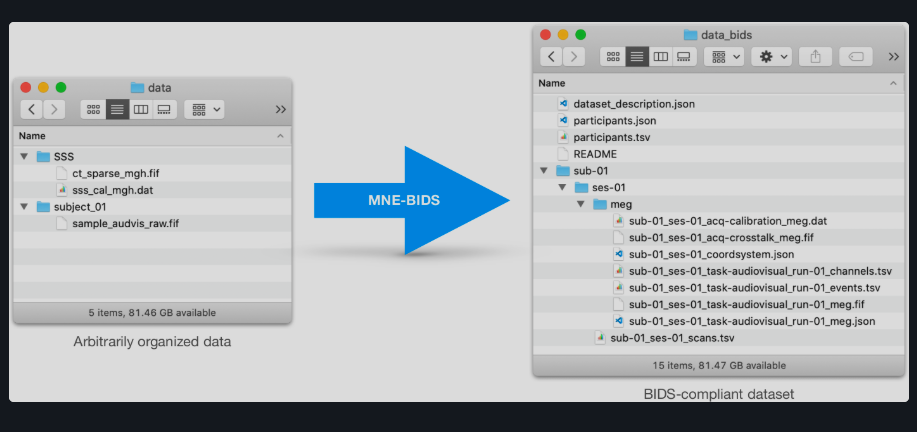

mne bids: is mne package to for read and write bids data


when you organize data in bids you can run tools on your data that expect bids data :)))))

In [1]:
import matplotlib
import pathlib

import mne
import mne_bids

matplotlib.use('QtAgg')

# Read the input data we wish to convert to BIDS

In [2]:
sample_data_dir = mne.datasets.sample.data_path()
sample_data_dir_path_lib = pathlib.Path(sample_data_dir)
raw_path = sample_data_dir_path_lib / 'MEG' / 'sample' / 'sample_audvis_raw.fif'
raw = mne.io.read_raw(raw_path)
print(f"sample_data_dir_pahtlib: {sample_data_dir_path_lib}\n {'='*60}\n raw path: {raw_path}")
events = mne.find_events(raw)
event_id = {
    'Auditory/Left': 1,
    'Auditory/Right':2,
    'Visual/Left': 3,
    'Visual/Right': 4,
    'Smiley': 5,
    'Button' : 32
}
event_id

Opening raw data file C:\Users\Zakaria\mne_data\MNE-sample-data\MEG\sample\sample_audvis_raw.fif...


c:\Users\Zakaria\Downloads\eeg_study\eeg-signal-processing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
sample_data_dir_pahtlib: C:\Users\Zakaria\mne_data\MNE-sample-data
 raw path: C:\Users\Zakaria\mne_data\MNE-sample-data\MEG\sample\sample_audvis_raw.fif
Finding events on: STI 014
320 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]


{'Auditory/Left': 1,
 'Auditory/Right': 2,
 'Visual/Left': 3,
 'Visual/Right': 4,
 'Smiley': 5,
 'Button': 32}

# Write the raw data to BIDS

we need to specify the power line frequency

In [3]:
# data is recorded in US and the line freq hanek 60 HZ
raw.info['line_freq'] = 60

In [4]:
raw.info

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>

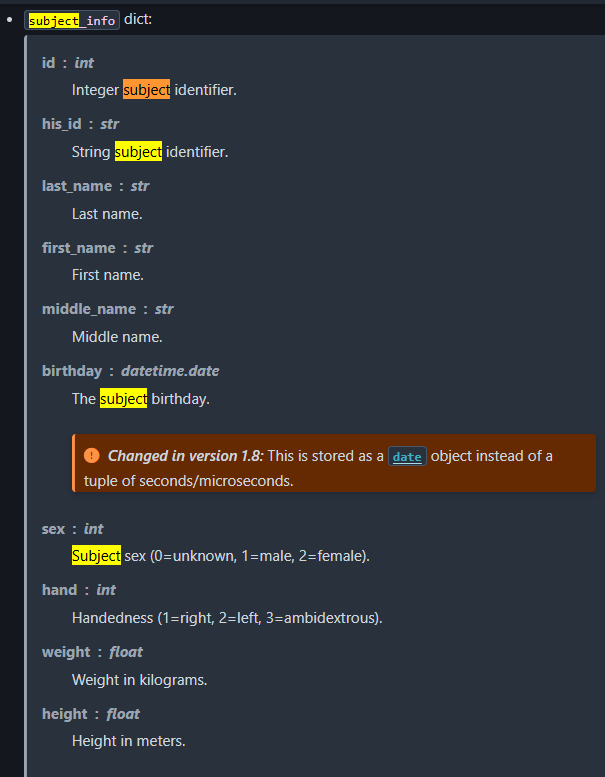

we need to add subject info in info datastructure

In [5]:
from datetime import date

# init the subject info as dic
subject_info = {
    'birthday': date(1988, 6, 11),
    'sex':  1,
    'hand': 3
}
raw.info['subject_info'] = subject_info
raw.info

<Info | 23 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
 subject_info: <subject_info | birthday: 1988-06-11, sex: 1, hand: 3>
>

now write the data

In [6]:
# specify output data directory 
out_path = pathlib.Path('out_data/sample_BIDS')

# BIDSPath is an object that represents a file path in a BIDS dataset.
# It uses the dataset root and BIDS entities (subject, session, task, run)
# to construct the path according to BIDS naming conventions.
# The entities you specify depend on how the dataset is organized.

bids_path = mne_bids.BIDSPath(
    subject='01',         # Participant ID
    session='01',         # Recording session ID
    task='audiovisual',   # Task name
    run='01',            # Recording run within this session and task
    root=out_path        # Root directory of the BIDS dataset
)

mne_bids.write_raw_bids(raw = raw,
                        bids_path=bids_path,
                        events=events,
                        event_id=event_id,
                        overwrite=True)

Opening raw data file C:\Users\Zakaria\mne_data\MNE-sample-data\MEG\sample\sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Writing 'out_data\sample_BIDS\participants.tsv'...
Writing 'out_data\sample_BIDS\participants.json'...
Writing 'out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_coordsystem.json'...
Used Annotations descriptions: ['Auditory/Left', 'Auditory/Right', 'Button', 'Smiley', 'Visual/Left', 'Visual/Right']
Writing 'out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_task-audiovisual_run-01_events.tsv'...
Writing 'out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_task-audiovisual_run-01_events.json'...
Writing 'out_data\sample_BIDS\dataset_description.json'...
Writing 'out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_task-audiovisual_run-01_meg.json'...
Copying data files to sub-01_ses-0

BIDSPath(
root: out_data/sample_BIDS
datatype: meg
basename: sub-01_ses-01_task-audiovisual_run-01_meg.fif)

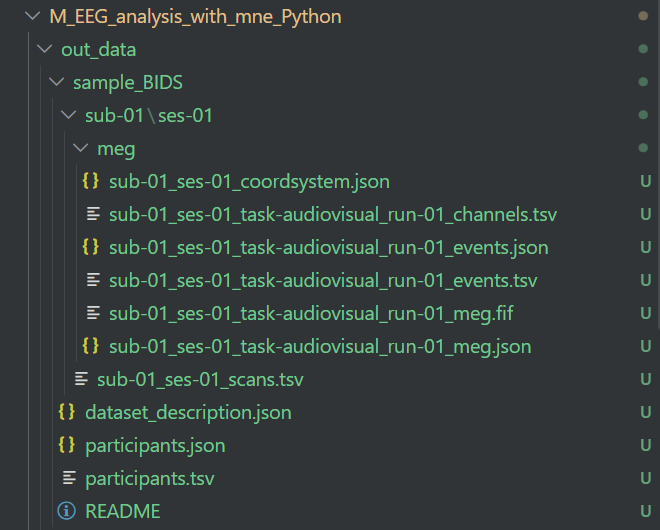

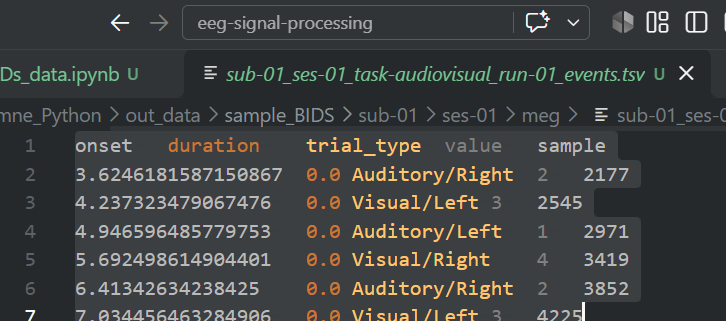

 onset: Event start time in seconds, relative to the start of the recording.
# duration: Event duration in seconds; 0 represents an instantaneous event marker.

# Write MEGIN / Elekta / NeuroMeg fine-calibration and crosstalk files

In [7]:
# if your data in meg requires this 2 files calibration, crosstalk files
cal_path = sample_data_dir / 'SSS' / 'sss_cal_mgh.dat'
ct_path = sample_data_dir / 'SSS' / 'ct_sparse_mgh.fif'

mne_bids.write_meg_calibration(cal_path,bids_path=bids_path)
mne_bids.write_meg_crosstalk(ct_path,bids_path=bids_path)


Writing fine-calibration file to out_data/sample_BIDS/sub-01/ses-01/meg/sub-01_ses-01_acq-calibration_meg.dat
Writing crosstalk file to out_data/sample_BIDS/sub-01/ses-01/meg/sub-01_ses-01_acq-crosstalk_meg.fif


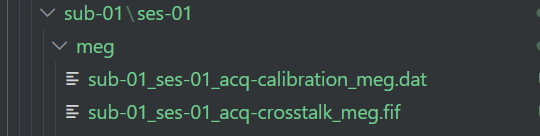

Added in the same file with correct bids naming

# Repeat the same thing but with assumption that our raw data is from session 2 

In [8]:
out_path = pathlib.Path('out_data/sample_BIDs')

bids_path = mne_bids.BIDSPath(
    subject='02',
    session= '01',
    task = 'audiovisual',
    run = '01',
    root = out_path
)

mne_bids.write_raw_bids(raw = raw,bids_path=bids_path,
                        events=events,event_id = event_id,overwrite=True)

# if your data in meg requires this 2 files calibration, crosstalk files
cal_path = sample_data_dir / 'SSS' / 'sss_cal_mgh.dat'
ct_path = sample_data_dir / 'SSS' / 'ct_sparse_mgh.fif'

mne_bids.write_meg_calibration(cal_path,bids_path=bids_path)
mne_bids.write_meg_crosstalk(ct_path,bids_path=bids_path)



Opening raw data file C:\Users\Zakaria\mne_data\MNE-sample-data\MEG\sample\sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Writing 'out_data\sample_BIDs\participants.tsv'...
Writing 'out_data\sample_BIDs\participants.json'...
Writing 'out_data\sample_BIDs\sub-02\ses-01\meg\sub-02_ses-01_coordsystem.json'...
Used Annotations descriptions: ['Auditory/Left', 'Auditory/Right', 'Button', 'Smiley', 'Visual/Left', 'Visual/Right']
Writing 'out_data\sample_BIDs\sub-02\ses-01\meg\sub-02_ses-01_task-audiovisual_run-01_events.tsv'...
Writing 'out_data\sample_BIDs\sub-02\ses-01\meg\sub-02_ses-01_task-audiovisual_run-01_events.json'...
Writing 'out_data\sample_BIDs\dataset_description.json'...
Writing 'out_data\sample_BIDs\sub-02\ses-01\meg\sub-02_ses-01_task-audiovisual_run-01_meg.json'...
Copying data files to sub-02_ses-0

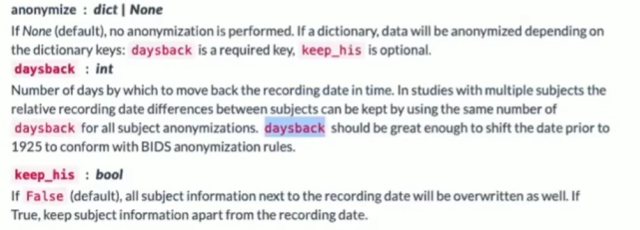

`anonymize` controls how identifying information is removed or changed:

- **`None`**: No anonymization is applied.
- **`daysback`**: Shifts the recording date backward by this number of days. Choose a value large enough to move the date before 1925, as described above.
- **`keep_his=False`**: Also replaces other participant information.
- **`keep_his=True`**: Keeps other participant information while shifting the recording date.

This changes metadata, not the recorded signal or event timing relative to the recording. Using the same `daysback` across recordings preserves the time differences between their dates.

# Print the created file and directory structure

In [9]:
mne_bids.print_dir_tree(out_path)

|sample_BIDs\
|--- README
|--- dataset_description.json
|--- participants.json
|--- participants.tsv
|--- sub-01\
|------ ses-01\
|--------- sub-01_ses-01_scans.tsv
|--------- meg\
|------------ sub-01_ses-01_acq-calibration_meg.dat
|------------ sub-01_ses-01_acq-crosstalk_meg.fif
|------------ sub-01_ses-01_coordsystem.json
|------------ sub-01_ses-01_task-audiovisual_run-01_channels.tsv
|------------ sub-01_ses-01_task-audiovisual_run-01_events.json
|------------ sub-01_ses-01_task-audiovisual_run-01_events.tsv
|------------ sub-01_ses-01_task-audiovisual_run-01_meg.fif
|------------ sub-01_ses-01_task-audiovisual_run-01_meg.json
|--- sub-02\
|------ ses-01\
|--------- sub-02_ses-01_scans.tsv
|--------- meg\
|------------ sub-02_ses-01_acq-calibration_meg.dat
|------------ sub-02_ses-01_acq-crosstalk_meg.fif
|------------ sub-02_ses-01_coordsystem.json
|------------ sub-02_ses-01_task-audiovisual_run-01_channels.tsv
|------------ sub-02_ses-01_task-audiovisual_run-01_events.json
|--

# Generate a data summary

In [10]:
print(mne_bids.make_report(out_path))

Summarizing participants.tsv out_data\sample_BIDs\participants.tsv...
Summarizing scans.tsv files [WindowsPath('out_data/sample_BIDs/sub-02/ses-01/sub-02_ses-01_scans.tsv'), WindowsPath('out_data/sample_BIDs/sub-01/ses-01/sub-01_ses-01_scans.tsv')]...
The participant template found: comprised of 2 male and 0 female participants;
comprised of 0 right hand, 0 left hand and 2 ambidextrous;
ages ranged from 14.0 to 14.0 (mean = 14.0, std = 0.0)
 The [Unspecified] dataset was created by [Unspecified1], and [Unspecified2] and
conforms to BIDS version 1.9.0. This report was generated with MNE-BIDS
(https://doi.org/10.21105/joss.01896). The dataset consists of 2 participants
(comprised of 2 male and 0 female participants; comprised of 0 right hand, 0
left hand and 2 ambidextrous; ages ranged from 14.0 to 14.0 (mean = 14.0, std =
0.0)) and 1 recording sessions: 01. Data was recorded using an MEG system
(Elekta) sampled at 600.61 Hz with line noise at 60.0 Hz. The following software
filters were

# Reading BIDS data

lets try to read back the data we just stored according to the BIDS specifiaction

In [11]:
bids_root = pathlib.Path('out_data/sample_BIDS')

bids_path = mne_bids.BIDSPath(
    subject = '01',
    session='01',
    task='audiovisual',
    run='01',
    datatype='meg',
    root=bids_root
)

raw = mne_bids.read_raw_bids(bids_path)

Opening raw data file out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_task-audiovisual_run-01_meg.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading channel info from out_data\sample_BIDS\sub-01\ses-01\meg\sub-01_ses-01_task-audiovisual_run-01_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info


In [12]:
raw.plot()

Using qt as 2D backend.


Waiting for Loading-Thread to finish... (max. 10 sec)
Channels marked as bad:
['MEG 2443', 'EEG 053']


# Events are stored as annotations - but we convet between the two.

In [14]:
raw.annotations[-1]

OrderedDict([('onset', np.float64(280.8321518290534)),
             ('duration', np.float64(0.0)),
             ('description', 'Button'),
             ('orig_time',
              datetime.datetime(2002, 12, 3, 19, 1, 10, 720100, tzinfo=datetime.timezone.utc)),
             ('extras', {})])

In [ ]:
mne.events_from_annotations?

In [ ]:
# some times we need events rather that annotation 
# in case if we want to make epoching with this
# events mne excpect to input events not annotaions
events, event_id = mne.events_from_annotations(raw)

events, events.shape, event_id

In [ ]:
mne.viz.plot_events(events=events,event_id=event_id,sfreq=raw.info['sfreq'])

# Fine the MEG fine-calibration and crpsstalk files

In [17]:
bids_path.meg_calibration_fpath

WindowsPath('out_data/sample_BIDS/sub-01/ses-01/meg/sub-01_ses-01_acq-calibration_meg.dat')

In [18]:
bids_path.meg_crosstalk_fpath

WindowsPath('out_data/sample_BIDS/sub-01/ses-01/meg/sub-01_ses-01_acq-crosstalk_meg.fif')

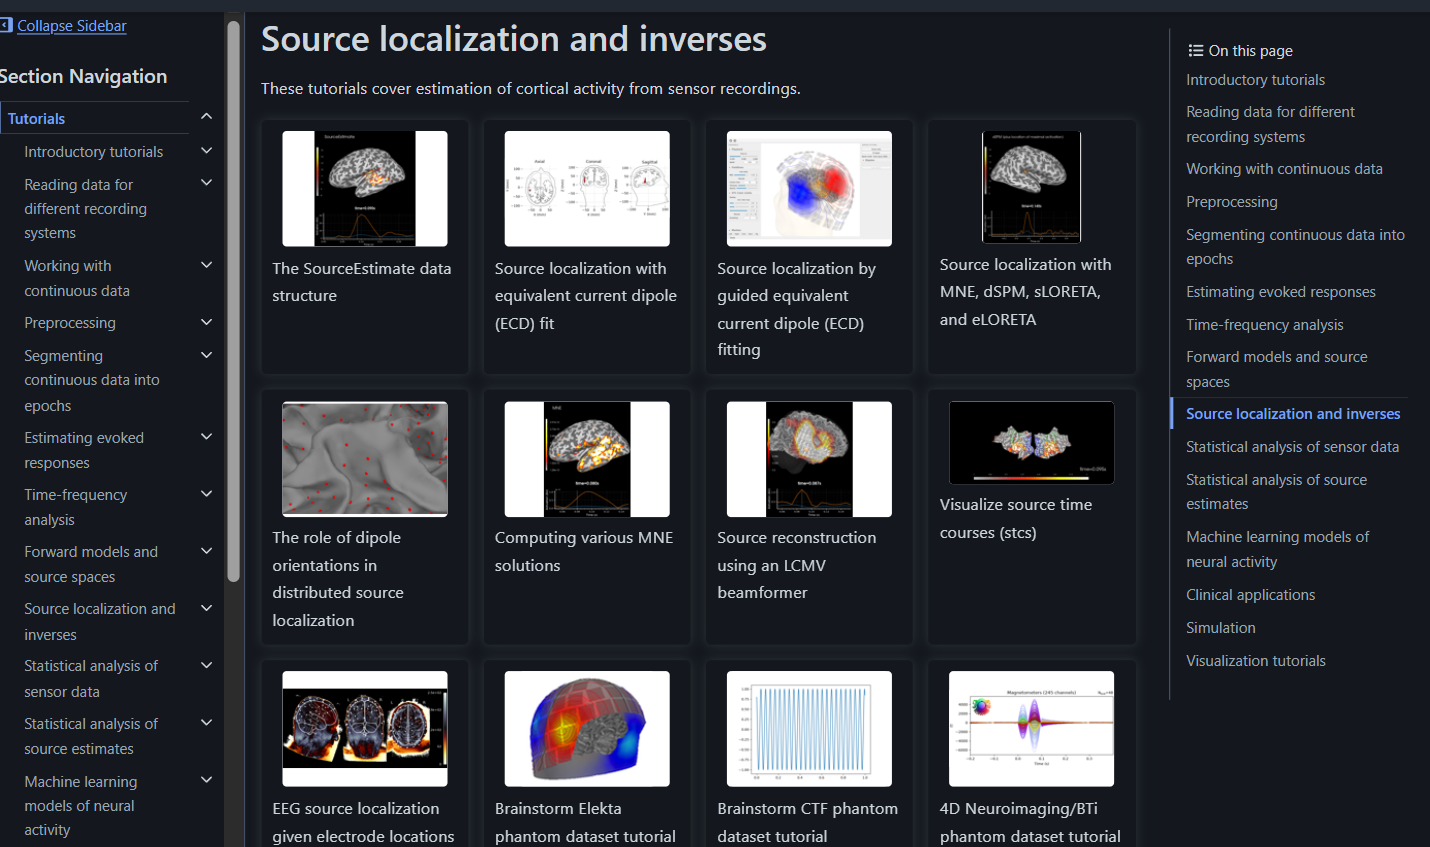


look at this tutorials